# Pergunta 2.4: o que mais pesa na nota? Faz sentido para o negócio?

> **Pergunta do case:** feature importance: quais variáveis mais influenciam o score? Isso faz sentido do ponto de vista de negócio?

| Passo | Pergunta |
|---|---|
| 1 | Quantos pontos vale cada coluna? (pesos da regressão linear) |
| 2 | Qual variável, inteira, mais ajuda a prever? (importância por permutação) |
| 3 | A Random Forest concorda? |
| 4 | Os pesos são estáveis? |
| 5 | Linear × Random Forest × Parte 1 |
| 6 | E no Modelo B? |
| 7 | A leitura para o negócio |

Tudo usa só o **treino**: o teste já foi usado, uma única vez, no notebook 2.3.

## Passo 0: preparação

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

RAIZ = Path("../..")
sys.path.append(str(RAIZ))
from src.avaliacao import dobras
from src.features import (ALVO, CATEGORIAS_A, COLUNAS_A, COLUNAS_B, NOVAS_A, NUMERICAS, carregar_treino_teste,
                          efeitos_em_pontos, montar_pipeline)

pd.set_option("display.width", 200)
AZUL, VERMELHO, CINZA, CINZA_CLARO = "#2a78d6", "#d64a2a", "#52514e", "#b8b7b1"
plt.rcParams.update({"font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left"})
PASTA_FIGURAS = RAIZ / "reports/figures"

treino, _ = carregar_treino_teste(RAIZ / "data/raw/klike_challenge_dataset.csv")
y = treino[ALVO]
modelo_A, modelo_B = joblib.load(RAIZ / "models/modelo_A.joblib"), joblib.load(RAIZ / "models/modelo_B.joblib")
cortes = dobras(treino)

NOMES = {"has_hook": "Gancho", "has_face": "Rosto", "has_cta": "CTA", "has_subtitle_sim": "Legenda (× não ter)",
         "has_subtitle_desconhecido": "Legenda desconhecida", "text_density_low": "Pouco texto (× médio)",
         "text_density_high": "Muito texto (× médio)", "format_vertical": "Vertical (× quadrado)",
         "format_horizontal": "Horizontal (× quadrado)", "video_duration_s": "Duração (por segundo)",
         "music_voice_ratio": "Só música (× só voz)", "musica_x_tiktok": "Só música no TikTok (a mais)",
         "is_retargeting": "Retargeting", "platform_TikTok": "TikTok (× Meta)", "platform_LinkedIn": "LinkedIn (× Meta)"}

## Passo 1: quantos pontos vale cada coluna?

Duas leituras do mesmo modelo (a regressão linear do notebook 2.2):
- **Peso em pontos:** quantos pontos de nota a coluna soma, **mantendo todo o resto igual**. Para uma coluna 0/1: "ter gancho" contra "não ter". É a leitura que vai para a Parte 3.
- **Peso padronizado:** quantos pontos a nota muda quando a coluna muda **um desvio padrão**. Serve para comparar colunas em escalas diferentes (segundos × sim/não). É o peso que o modelo realmente usa, porque as colunas são padronizadas no Pipeline.

O intervalo vem das 15 provas da validação cruzada: o modelo é treinado 15 vezes, cada uma com 80% do treino, e anoto o peso de cada vez. Mostro do menor ao maior valor.

In [2]:
pesos_por_prova = pd.DataFrame([efeitos_em_pontos(clone(modelo_A).fit(treino.iloc[dentro][COLUNAS_A], y.iloc[dentro]),
                                                  treino[COLUNAS_A]) for dentro, _ in cortes])
pesos = pd.DataFrame({
    "peso (pontos)": efeitos_em_pontos(modelo_A, treino[COLUNAS_A]),
    "menor nas 15 provas": pesos_por_prova.min(), "maior nas 15 provas": pesos_por_prova.max(),
    "peso padronizado": pd.Series(modelo_A[-1].coef_, index=pesos_por_prova.columns),
})
pesos["mesmo sinal nas 15?"] = np.sign(pesos_por_prova).nunique() == 1
pesos.sort_values("peso padronizado", key=abs, ascending=False).round(2)

,peso (pontos),menor nas 15 provas,maior nas 15 provas,peso padronizado,mesmo sinal nas 15?
has_hook,17.92,17.39,18.36,8.96,True
has_face,11.53,10.84,12.23,5.75,True
text_density_high,-15.09,-16.58,-14.52,-5.70,True
has_subtitle_sim,8.07,7.43,8.84,4.03,True
text_density_low,-7.61,-8.26,-7.05,-3.69,True
has_cta,7.52,6.49,8.16,3.45,True
platform_TikTok,6.45,5.12,7.80,3.08,True
musica_x_tiktok,-11.52,-14.94,-8.34,-2.53,True
is_retargeting,4.35,3.70,5.07,1.86,True
objective_engagement,-4.79,-5.90,-3.31,-1.78,True


**Lendo os pesos:**

- **Os maiores, em pontos (mantendo o resto igual):** gancho **+17,9**; muito texto **−15,1** (contra texto médio); rosto **+11,5**; legenda **+8,1** (contra não ter); pouco texto **−7,6**; CTA **+7,5**.
- **No TikTok, a voz importa:** nas outras redes, trocar "só voz" por "só música" não muda nada (−0,03 ponto). No TikTok, custa **11,5 pontos** (a coluna música × TikTok). O peso do próprio TikTok (+6,5 contra o Meta) vale para um vídeo com voz e deve ser lido junto com essa coluna, porque as duas andam juntas.
- **Contexto:** retargeting +4,4; os outros objetivos ficam de 3 a 6 pontos abaixo de conversions; o LinkedIn, 3,7 abaixo do Meta.
- **A duração não pesa:** 0,02 ponto por segundo (0,2 a cada 10 s).
- **O peso padronizado dá a mesma ordem** (gancho 9,0, rosto 5,8, muito texto 5,7). Todos os pesos grandes têm o mesmo sinal nas 15 provas; os que trocam de sinal são todos pequenos (até 1,4 ponto): horizontal, idades acima de 35, duração e indicadores de vazio.

## Passo 2: qual variável, inteira, mais ajuda a prever?

Os pesos de uma variável de texto ficam espalhados em vários níveis (texto pouco, texto muito...). Para saber quanto a variável **inteira** importa, uso a **importância por permutação**: embaralho os valores de uma coluna (por exemplo, sorteio de novo quem tem gancho) e vejo quanto o erro piora. Se piora muito, o modelo dependia dela. É como tirar uma peça de um motor e ver o quanto ele perde força.

- Embaralho a **coluna original** (antes do one-hot), então os níveis de `text_density` saem juntos, e a música/voz leva junto a interação com o TikTok.
- Meço na parte de **validação** de cada uma das 15 provas (dados que o modelo não viu), 10 embaralhadas por coluna.
- Resultado: quantos pontos o MAE sobe sem aquela variável.

In [3]:
def permutacao(modelo, colunas, novas=NOVAS_A, numericas=NUMERICAS):
    """Aumento do MAE (pontos) ao embaralhar cada coluna, na validação de cada prova."""
    linhas = []
    for dentro, fora in cortes:
        ajustado = clone(modelo).fit(treino.iloc[dentro][colunas], y.iloc[dentro])
        resultado = permutation_importance(ajustado, treino.iloc[fora][colunas], y.iloc[fora], n_repeats=10,
                                           scoring="neg_mean_absolute_error", random_state=42)
        linhas.append(pd.Series(resultado.importances_mean, index=colunas))
    return pd.DataFrame(linhas)


importancia_A = permutacao(modelo_A, COLUNAS_A)
resumo_A = pd.DataFrame({"MAE sobe (pontos)": importancia_A.mean(), "desvio entre provas": importancia_A.std()})
resumo_A = resumo_A.sort_values("MAE sobe (pontos)", ascending=False)
resumo_A.round(2)

,MAE sobe (pontos),desvio entre provas
has_hook,5.55,0.41
has_face,2.69,0.29
text_density,2.38,0.43
has_subtitle,1.20,0.21
has_cta,1.04,0.21
platform,0.37,0.15
is_retargeting,0.33,0.17
objective,0.28,0.21
format,0.10,0.08
music_voice_ratio,0.07,0.12


**Lendo a permutação:**

- **Embaralhar o gancho faz o erro subir 5,6 pontos** (de 6,9 para cerca de 12,5, perto do erro de quem chuta a média). Depois vêm rosto (+2,7), texto na tela (+2,4), legenda (+1,2) e CTA (+1,0).
- **Os cinco primeiros são todos atributos do vídeo.** O contexto vem depois e pesa pouco: plataforma +0,37, retargeting +0,33, objetivo +0,28.
- **Formato, música/voz, idade e duração quase não ajudam a prever** (até 0,1 ponto). A música/voz fica baixa porque só pesa no TikTok. A duração dá um pouco negativo: embaralhá-la não faz diferença, e o que sobra é ruído.

## Passo 3: a Random Forest concorda?

Na Random Forest não há pesos. Há duas medidas de importância:
- **Importância padrão (da árvore):** quanto cada coluna ajudou a separar os criativos nas perguntas das árvores, medida **no treino**. Ela favorece colunas com muitos valores diferentes (como a duração), porque elas oferecem mais perguntas possíveis, mesmo sem sinal real.
- **Importância por permutação:** a mesma do passo 2, medida na **validação**. É mais confiável: mede o quanto a previsão piora em dados novos.

A floresta usa os hiperparâmetros escolhidos no notebook 2.2 (`min_samples_leaf` = 3, `max_features` = 0,5) e o `n_boas_praticas`.

In [4]:
NOVAS_FLORESTA = NOVAS_A + ["n_boas_praticas"]
floresta = montar_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, random_state=42, n_jobs=-1),
                           NUMERICAS, CATEGORIAS_A, NOVAS_FLORESTA).fit(treino[COLUNAS_A], y)
colunas_floresta = floresta[:-1].transform(treino[COLUNAS_A].head()).columns
padrao = pd.Series(floresta[-1].feature_importances_, index=colunas_floresta)
# Soma os níveis de cada variável original (one-hot e indicador de vazio voltam para a coluna de origem)
origem = {c: next((o for o in COLUNAS_A if c == o or c.startswith(o + "_") or c == f"missingindicator_{o}"), c) for c in colunas_floresta}
padrao_agrupada = padrao.groupby(origem).sum()

importancia_floresta = permutacao(floresta, COLUNAS_A, NOVAS_FLORESTA)
floresta_comparada = pd.DataFrame({"padrão (% do total)": padrao_agrupada / padrao_agrupada.sum() * 100,
                                   "permutação: MAE sobe (pontos)": importancia_floresta.mean()})
floresta_comparada.sort_values("permutação: MAE sobe (pontos)", ascending=False).round(2)

,padrão (% do total),permutação: MAE sobe (pontos)
has_hook,20.73,4.91
has_face,6.26,2.36
text_density,13.05,1.50
has_subtitle,1.96,1.07
has_cta,1.73,1.07
platform,2.31,0.11
format,2.37,0.08
is_retargeting,1.09,0.07
objective,2.03,0.03
target_audience_age,1.94,-0.00


**Lendo a Random Forest:**

- **A permutação concorda com o linear:** gancho (+4,9), rosto (+2,4), texto (+1,5), legenda e CTA (+1,1 cada); o contexto fica perto de zero.
- **A importância padrão discorda, e mostra os seus defeitos:**
  - `n_boas_praticas` fica com 34% do total, porque soma gancho, rosto, CTA e legenda e "rouba" o crédito deles;
  - duração e música/voz recebem cerca de 5% cada, mas na permutação valem zero. É o viés das colunas com muitos valores diferentes, que oferecem mais perguntas possíveis à árvore.
- Por isso confio na permutação. (As colunas criadas dentro do Pipeline, `musica_x_tiktok` e `n_boas_praticas`, não têm permutação própria: o crédito delas vai para as colunas de origem.)

## Passo 4: os pesos são estáveis?

Se o peso de uma coluna muda muito de uma prova para outra, não dá para confiar no número exato. O gráfico mostra, para as colunas do vídeo, o peso em cada uma das 15 provas.

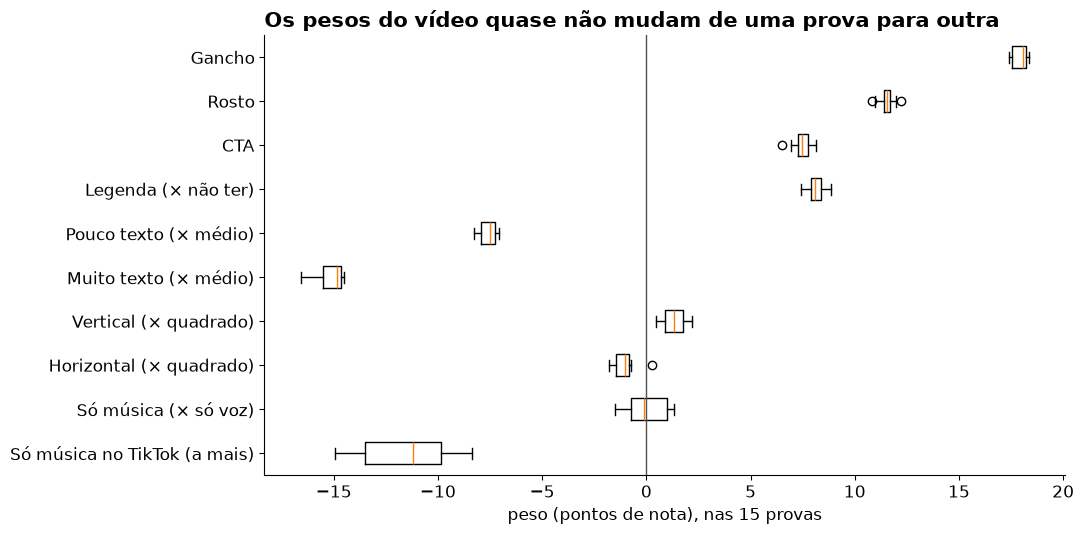

Em quantas das 15 provas cada coluna ficou entre as 3 maiores (em pontos):
Muito texto (× médio)           15
Gancho                          15
Rosto                            8
Só música no TikTok (a mais)     7


In [5]:
colunas_video = ["has_hook", "has_face", "has_cta", "has_subtitle_sim", "text_density_low", "text_density_high",
                 "format_vertical", "format_horizontal", "music_voice_ratio", "musica_x_tiktok"]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.boxplot([pesos_por_prova[c] for c in colunas_video[::-1]], orientation="horizontal",
           tick_labels=[NOMES[c] for c in colunas_video[::-1]])
ax.axvline(0, color=CINZA, linewidth=1)
ax.set_xlabel("peso (pontos de nota), nas 15 provas")
ax.set_title("Os pesos do vídeo quase não mudam de uma prova para outra")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

ranking_por_prova = pesos_por_prova.abs().rank(axis=1, ascending=False)
print("Em quantas das 15 provas cada coluna ficou entre as 3 maiores (em pontos):")
print((ranking_por_prova <= 3).sum().loc[lambda s: s > 0].sort_values(ascending=False).rename(index=NOMES).to_string())

**Os pesos do vídeo são estáveis:**

- **Gancho e muito texto ficam entre os 3 maiores nas 15 provas,** e os intervalos são estreitos (o gancho vai de 17,4 a 18,4 pontos).
- **O 3º lugar se divide entre o rosto (8 provas) e a música × TikTok (7).** Esta última é a que mais varia (de −14,9 a −8,3): tem menos criativos e anda junto com a coluna do TikTok. Quando duas colunas andam juntas, a regressão linear não sabe a qual dar o crédito, e os pesos das duas variam mais. Por isso essa recomendação deve ser apresentada como "cerca de 10 pontos", não como um número exato.

## Passo 5: linear × Random Forest × Parte 1

Três rankings independentes das variáveis do vídeo. A coluna da Parte 1 usa os pesos da regressão do notebook 1.2 (em pontos; valores copiados daquele notebook, que usava só criativos sem vazio e ainda tinha a `category`).

In [6]:
PARTE_1 = {"has_hook": 17.5, "text_density": -15.1, "has_face": 11.8, "has_subtitle": 7.9, "has_cta": 7.2,
           "format": 1.2, "music_voice_ratio": -4.1, "video_duration_s": 0.3}  # notebook 1.2, passo 6 (pontos)
variaveis_video = list(PARTE_1)
rankings = pd.DataFrame({
    "linear (permutação)": importancia_A.mean()[variaveis_video].rank(ascending=False),
    "Random Forest (permutação)": importancia_floresta.mean()[variaveis_video].rank(ascending=False),
    "Random Forest (padrão)": padrao_agrupada[variaveis_video].rank(ascending=False),
    "Parte 1 (|peso|)": pd.Series(PARTE_1).abs().rank(ascending=False),
}).astype(int).sort_values("linear (permutação)")
rankings

,linear (permutação),Random Forest (permutação),Random Forest (padrão),Parte 1 (|peso|)
has_hook,1,1,1,1
has_face,2,2,3,3
text_density,3,3,2,2
has_subtitle,4,4,7,4
has_cta,5,5,8,5
format,6,6,6,7
music_voice_ratio,7,7,4,6
video_duration_s,8,8,5,8


**Os rankings quase coincidem:**

- **O gancho é o 1º em todos.** Rosto e texto ficam em 2º e 3º; legenda e CTA, em 4º e 5º; formato, música/voz e duração, no fim.
- **A única divergência é a importância padrão da Random Forest**, que sobe música/voz e duração (o viés do passo 3) e rebaixa legenda e CTA (o crédito foi para `n_boas_praticas`).
- **Rosto × texto trocam de lugar** conforme a medida. Em pontos, muito texto (−15,1) pesa mais que o rosto (+11,5), como na Parte 1. Na permutação, o rosto ganha: ele está em cerca de metade dos vídeos, e o muito texto só em 17%. **A importância depende de quantos criativos têm o atributo**, e não só do tamanho do efeito.

## Passo 6: e no Modelo B?

O Modelo B tem as métricas que só existem depois de postar. Se uma delas dominar, é esperado: a nota mede o desempenho, e o CTR **é** desempenho. Mas isso não serve ao produto, porque, no momento de dar a nota, essas métricas ainda não existem.

In [7]:
importancia_B = permutacao(modelo_B, COLUNAS_B, numericas=NUMERICAS + [c for c in COLUNAS_B if c not in COLUNAS_A])
importancia_B.mean().sort_values(ascending=False).round(2).rename("MAE sobe (pontos)").to_frame()

,MAE sobe (pontos)
has_hook,4.12
has_face,2.36
text_density,2.01
has_cta,1.30
has_subtitle,1.18
ctr,1.10
retencao,0.54
objective,0.53
platform,0.44
log_conversoes,0.30


**Surpresa: mesmo no Modelo B, o vídeo domina.** Gancho (+4,1), rosto (+2,4), texto (+2,0), CTA (+1,3) e legenda (+1,2) vêm antes da primeira métrica pós-lançamento, o CTR (+1,1), seguido da retenção (+0,5).

- **Esperava o contrário:** a nota mede desempenho, e o CTR é desempenho.
- **O que isso diz:** as métricas pós-lançamento acrescentam pouco ao que o criativo já explica. Para o produto, é uma boa notícia: dá para avaliar antes de postar.
- **Cuidado:** num dataset simulado, a nota provavelmente foi gerada principalmente a partir dos atributos. Em dados reais, o CTR deve pesar mais.

## Passo 7: a leitura para o negócio

Duas figuras de apresentação (título = a conclusão; valores escritos; o que importa em cor).

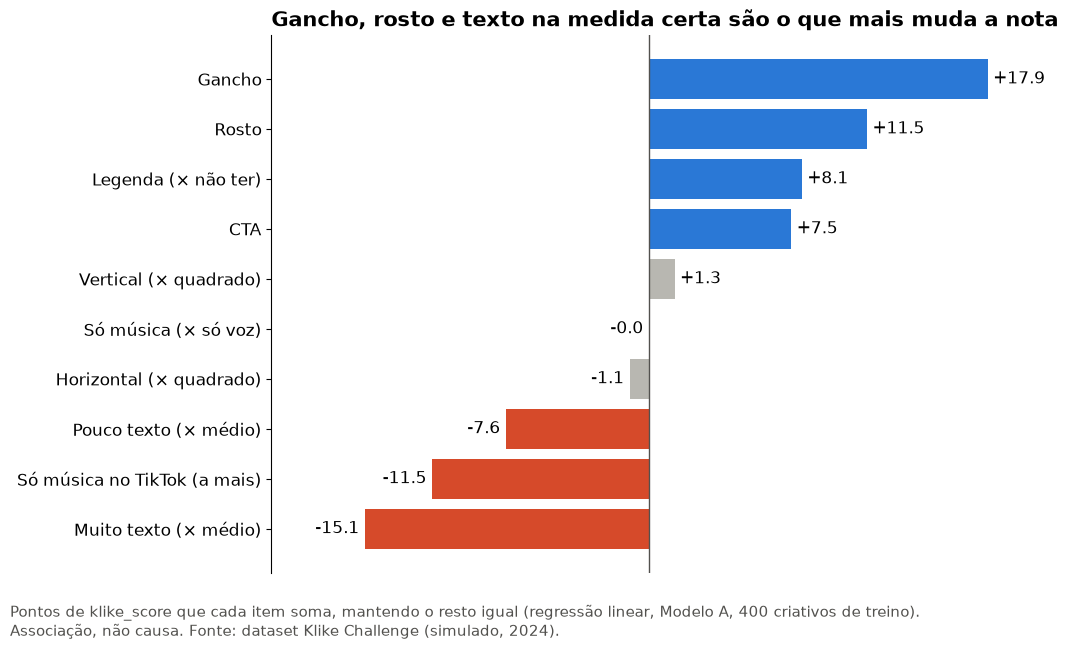

In [8]:
mostrar = ["has_hook", "has_face", "has_subtitle_sim", "has_cta", "format_vertical", "format_horizontal",
           "music_voice_ratio", "musica_x_tiktok", "text_density_low", "text_density_high"]
efeito = pesos.loc[mostrar, "peso (pontos)"].sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
cores = [AZUL if v >= 3 else VERMELHO if v <= -3 else CINZA_CLARO for v in efeito]
barras = ax.barh([NOMES[c] for c in efeito.index], efeito.values, color=cores)
ax.bar_label(barras, labels=[f"{v:+.1f}" for v in efeito.values], padding=4, fontsize=12)
ax.axvline(0, color=CINZA, linewidth=1)
ax.set_xticks([])
ax.margins(x=0.15)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_title("Gancho, rosto e texto na medida certa são o que mais muda a nota")
fig.text(0.01, -0.02, "Pontos de klike_score que cada item soma, mantendo o resto igual (regressão linear, Modelo A, 400 criativos de treino).\n"
                      "Associação, não causa. Fonte: dataset Klike Challenge (simulado, 2024).", fontsize=11, color=CINZA, va="top")
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "parte2_fig1_o_que_pesa_na_nota.png", dpi=150, bbox_inches="tight")
plt.show()

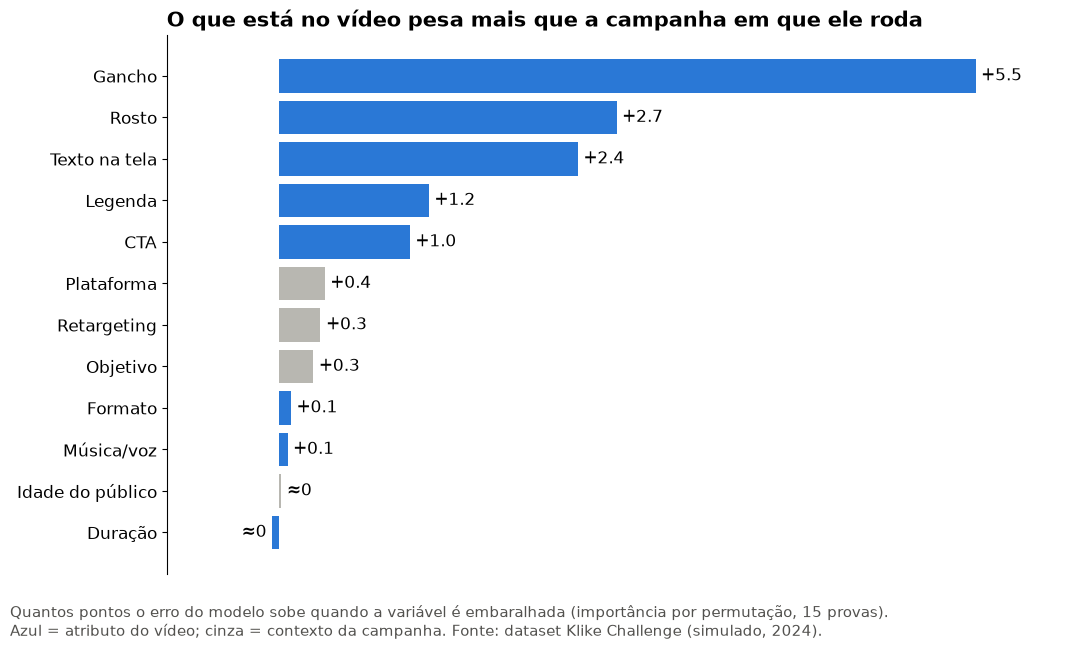

In [9]:
NOMES_VARIAVEIS = {"has_hook": "Gancho", "text_density": "Texto na tela", "has_face": "Rosto", "has_subtitle": "Legenda",
                   "has_cta": "CTA", "objective": "Objetivo", "platform": "Plataforma", "music_voice_ratio": "Música/voz",
                   "target_audience_age": "Idade do público", "is_retargeting": "Retargeting", "format": "Formato",
                   "video_duration_s": "Duração"}
importancia = importancia_A.mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
cores = [AZUL if c in PARTE_1 else CINZA_CLARO for c in importancia.index]
barras = ax.barh([NOMES_VARIAVEIS[c] for c in importancia.index], importancia.values, color=cores)
ax.bar_label(barras, labels=[f"+{v:.1f}" if v >= 0.05 else "≈0" for v in importancia.values], padding=4, fontsize=12)
ax.set_xticks([])
ax.margins(x=0.15)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_title("O que está no vídeo pesa mais que a campanha em que ele roda")
fig.text(0.01, -0.02, "Quantos pontos o erro do modelo sobe quando a variável é embaralhada (importância por permutação, 15 provas).\n"
                      "Azul = atributo do vídeo; cinza = contexto da campanha. Fonte: dataset Klike Challenge (simulado, 2024).",
         fontsize=11, color=CINZA, va="top")
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "parte2_fig2_video_pesa_mais_que_campanha.png", dpi=150, bbox_inches="tight")
plt.show()

**Faz sentido para o negócio?**

| O modelo diz | A Parte 1 dizia | Faz sentido? |
|---|---|---|
| gancho **+17,9 pontos** | +17,5 | sim: os 3 primeiros segundos decidem se a pessoa para de rolar o feed |
| rosto **+11,5** | +11,8 | sim: rosto humano prende a atenção e passa confiança |
| muito texto **−15,1**, pouco texto **−7,6** (contra médio) | −15,1 e −8,0 | sim: texto demais vira "slide"; pouco texto perde quem assiste sem som |
| legenda **+8,1** | +7,9 | sim: muita gente assiste sem som |
| CTA **+7,5** | +7,2 | sim: dizer o que fazer aumenta a ação |
| só música no TikTok: **−11,5** (nas outras redes, 0) | −13,4 (regressão só no TikTok) | sim: no TikTok, voz e narração são a linguagem da rede |
| formato e duração: **quase zero** | quase zero | nestes dados, sim; em dados reais, a duração costuma importar mais (ressalva) |
| retargeting **+4,4** | +4,5 | sim: quem já conhece a marca responde melhor; é efeito do público, não do vídeo |

Para o time de marketing, em uma frase: **comece pelo gancho, mostre um rosto, use texto na medida, legende, termine com uma chamada para ação e, no TikTok, use voz.**

**Ressalvas:**

- **Associação, não causa.** "Gancho vale +17 pontos" quer dizer que vídeos com gancho têm nota maior, mantendo o resto igual nestes dados. A prova de causa seria um teste A/B.
- **Colunas que andam juntas dividem a importância** (TikTok e música × TikTok): leia as duas juntas.
- **O dataset é simulado**, e a nota provavelmente foi gerada a partir destes mesmos atributos, quase somando efeitos. Isso ajuda a explicar por que um modelo linear simples vai tão bem (R² de 0,7) e por que os pesos são tão estáveis. Em dados reais, espere um R² menor e efeitos menos limpos.
- **"Tem gancho" não diz se o gancho é bom.** Os 30% da nota que o modelo não explica provavelmente estão na qualidade de execução, que as colunas não medem.

## Resposta à pergunta 2.4: quais variáveis mais influenciam a nota, e isso faz sentido para o negócio?

> 💡 **Conclusão**
>
> - **As que mais influenciam são atributos do vídeo:** gancho (+18 pontos), texto na tela na medida certa (muito texto tira 15, pouco texto tira 8), rosto (+12), legenda (+8) e CTA (+8). No TikTok, vídeo só com música, sem voz, perde cerca de 10 pontos. O contexto da campanha (rede, objetivo, público) pesa bem menos.
> - **Três jeitos de medir concordam:** os pesos da regressão linear, a importância por permutação (no linear e na Random Forest) e a Parte 1 dão o mesmo ranking, e os pesos quase não mudam entre as 15 provas.
> - **Faz sentido para o negócio:** cada efeito tem uma explicação de marketing (os primeiros segundos seguram a atenção, o rosto gera confiança, muita gente assiste sem som), e a exceção do TikTok (voz) aparece no modelo. Mesmo com as métricas pós-lançamento, o vídeo domina: bom sinal para avaliar antes de postar.
> - **Cuidado:** é associação, não causa, num dataset simulado. A prova seria um teste A/B.